In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
from pathlib import Path

if (not Path("data/us_employment.csv").exists()) and Path("sprint-5/data/us_employment.csv").exists():
    os.chdir("sprint-5")
os.environ["NIXTLA_ID_AS_COL"] = "true"
import numpy as np
np.set_printoptions(suppress=True)
np.random.seed(1)
import random
random.seed(1)
import pandas as pd
pd.set_option("max_colwidth", 100)
pd.set_option("display.precision", 3)
from utilsforecast.plotting import plot_series as plot_series_utils
import seaborn as sns
sns.set_style("whitegrid")
import matplotlib.pyplot as plt
plt.style.use("ggplot")
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 100,
    "figure.constrained_layout.use": True,
    "font.size": 11.5,
    "axes.titlesize": 14,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 9.5,
    "legend.title_fontsize": 11.5,
    "grid.alpha": 1.0,
})
import matplotlib as mpl
from cycler import cycler
mpl.rcParams['axes.prop_cycle'] = cycler(color=["#000000", "#000000"])

def plot_series(*args, xlabel=None, ylabel=None, title=None, **kwargs):
    fig = plot_series_utils(*args, **kwargs)
    if fig is None:
        fig = plt.gcf()
    ax = fig.axes[0] if getattr(fig, "axes", None) else plt.gca()
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if title is not None:
        ax.set_title(title)
    return fig

mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#2f2fff"], name="black_and_blue"),
    force=True,
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#D55E00"], name="black_and_orange"),
    force=True,
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#000000"], name="black"),
    force=True,
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#0072B2", "#D55E00"],
        name='black_and_2color',
    ),
    force=True
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#D55E00", "#0072B2", "#009E73"],
        name='black_and_3color',
    ),
    force=True
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#000000", "#D55E00", "#0072B2", "#009E73", "#CC79A7"],
        name='black_and_4color',
    ),
    force=True
)
mpl.colormaps.register(
    mpl.colors.ListedColormap(
        ["#D55E00", "#0072B2", "#009E73", "#CC79A7"],
        name='r_colors',
    ),
    force=True
)

import calendar
from coreforecast.scalers import boxcox, boxcox_lambda
from statsmodels.tsa.seasonal import STL, seasonal_decompose

os.makedirs("images", exist_ok=True)
print("cwd:", os.getcwd())


cwd: c:\Users\amelu\OneDrive\Desktop\я\qwant-mentorstvo\quant-research-mentorstvo\sprint-5


In [2]:
us_employment = pd.read_csv("data/us_employment.csv", parse_dates=["ds"])
us_retail_employment = us_employment.loc[lambda x:
    (x["unique_id"] == "Retail Trade") & (x["ds"] >= "1990")
]
fig = plot_series(us_retail_employment,
    xlabel="Month [1M]", ylabel="Persons (thousands)",
    title="Total employment in US retail")
fig.savefig("images/fig_3_5_us_retail_employment.png", dpi=150)
plt.show()


In [3]:
stl = STL(us_retail_employment["y"], period=12)
res = stl.fit()
dcmp = pd.DataFrame({
    "ds": us_retail_employment["ds"],
    "data": us_retail_employment["y"],
    "trend": res.trend,
    "seasonal": res.seasonal,
    "remainder": res.resid,
}).reset_index(drop=True)
dcmp.head()


,ds,data,trend,seasonal,remainder
0,1990-01-01,13255.8,13296.249,-3.700,-36.749
1,1990-02-01,12966.3,13276.085,-288.398,-21.387
2,1990-03-01,12938.2,13255.663,-306.658,-10.805
3,1990-04-01,13012.3,13234.986,-235.775,13.089
4,1990-05-01,13108.3,13214.071,-115.399,9.628


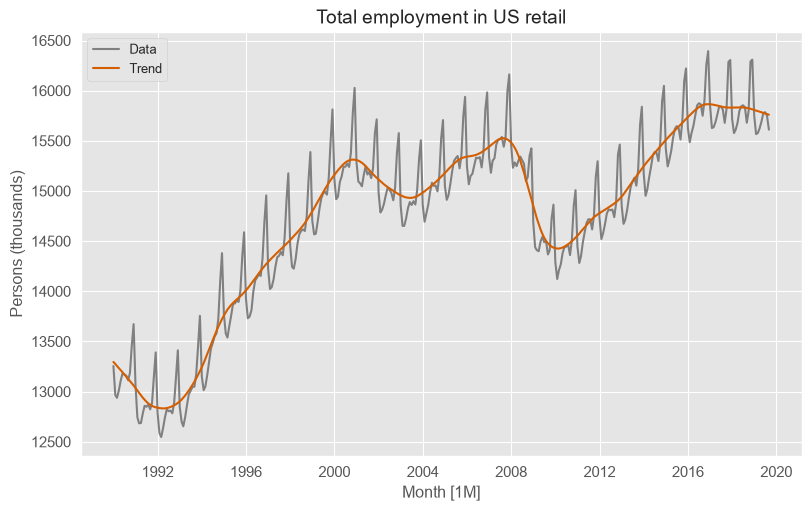

In [4]:
fig, ax = plt.subplots()
sns.lineplot(data=dcmp, x="ds", y="data", color="gray", label="Data")
sns.lineplot(data=dcmp, x="ds", y="trend", color="#D55E00", label="Trend")
ax.set(
    title="Total employment in US retail",
    xlabel="Month [1M]",
    ylabel="Persons (thousands)",
)
plt.savefig("images/fig_3_6_trend_vs_data.png", dpi=150)
plt.show()


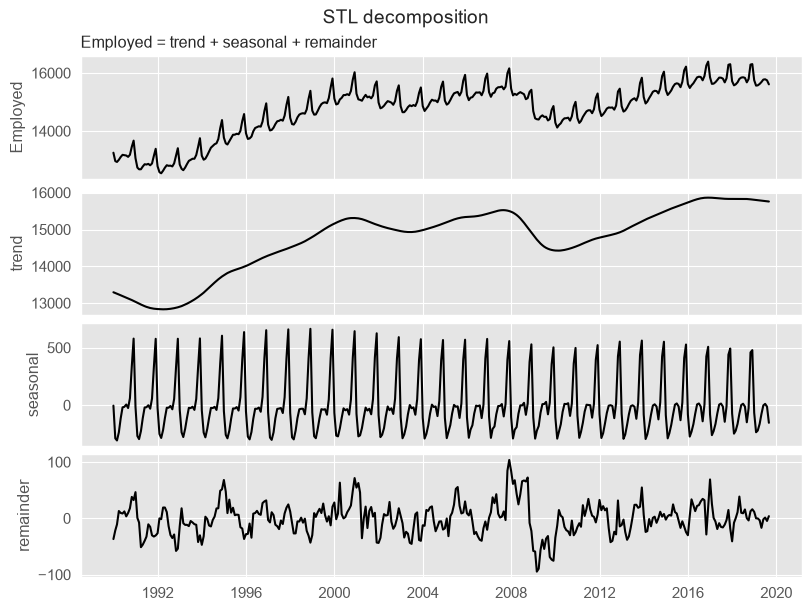

In [5]:
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(8, 6))
sns.lineplot(data=dcmp, x="ds", y="data", ax=axes[0])
sns.lineplot(data=dcmp, x="ds", y="trend", ax=axes[1])
sns.lineplot(data=dcmp, x="ds", y="seasonal", ax=axes[2])
sns.lineplot(data=dcmp, x="ds", y="remainder", ax=axes[3])
axes[0].set_title("Employed = trend + seasonal + remainder",
    size="medium", loc="left")
axes[0].set(ylabel="Employed")
axes[3].set(xlabel="")
fig.suptitle("STL decomposition")
plt.savefig("images/fig_3_7_stl_components.png", dpi=150)
plt.show()


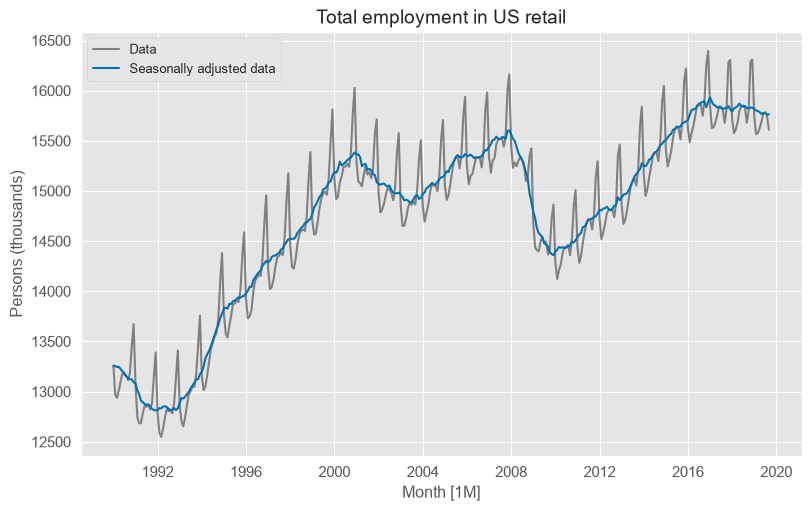

In [6]:
df = dcmp.assign(adj=lambda x: x["data"] - x["seasonal"])
fig, ax = plt.subplots()
sns.lineplot(data=df, x="ds", y="data", color="gray", label="Data")
sns.lineplot(data=df, x="ds", y="adj",
    color="#0072B2", label="Seasonally adjusted data")
ax.set(
    title="Total employment in US retail",
    xlabel="Month [1M]",
    ylabel="Persons (thousands)",
)
plt.savefig("images/fig_3_8_seasonally_adjusted.png", dpi=150)
plt.show()


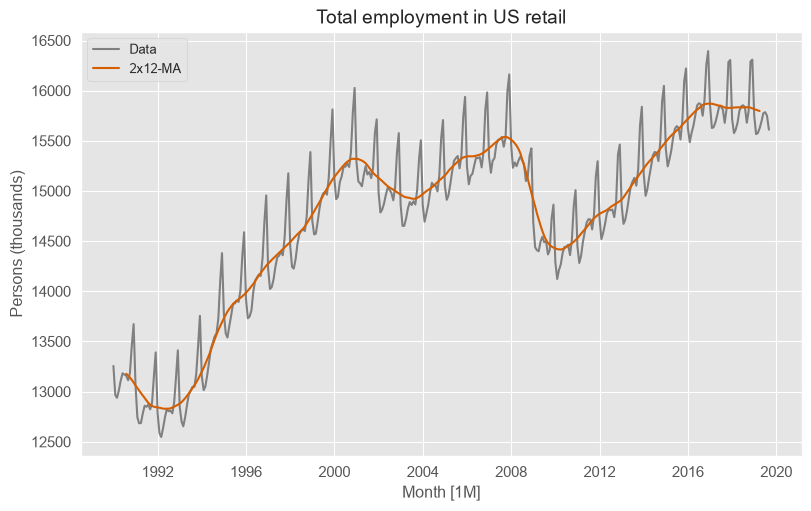

In [7]:
df = us_retail_employment.copy()
df["12-MA"] = df["y"].rolling(window=12, center=True).mean()
df["2x12-MA"] = df["12-MA"].rolling(window=2, center=True).mean()
fig, ax = plt.subplots()
sns.lineplot(data=df, x="ds", y="y", color="grey", label="Data")
sns.lineplot(data=df, x="ds", y="2x12-MA", color="#D55E00", label="2x12-MA")
ax.set(
    title="Total employment in US retail",
    xlabel="Month [1M]",
    ylabel="Persons (thousands)",
)
plt.savefig("images/fig_3_12_2x12_ma.png", dpi=150)
plt.show()


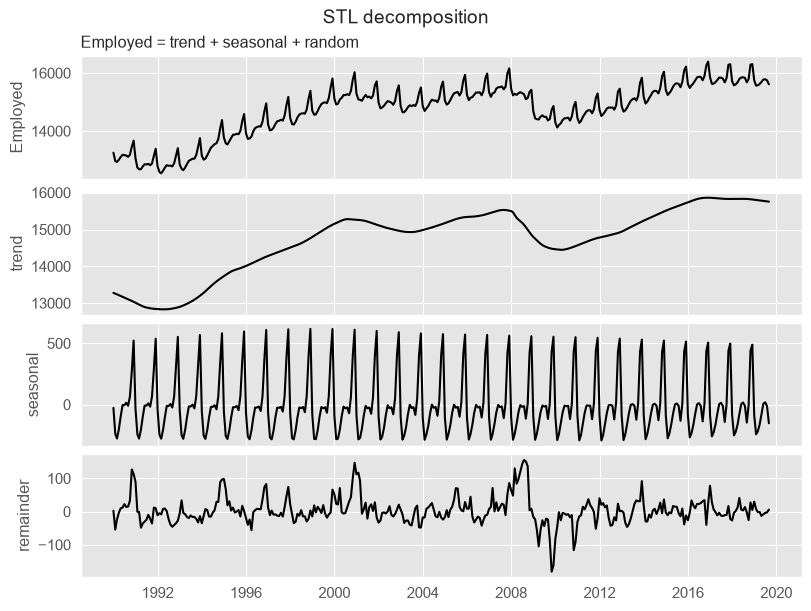

In [8]:
stl = STL(us_retail_employment["y"], period=12,
    seasonal=13, trend=21, robust=True)
res_stl = stl.fit()
dcmp = pd.DataFrame({
    "ds": us_retail_employment["ds"],
    "data": us_retail_employment["y"],
    "trend": res_stl.trend,
    "seasonal": res_stl.seasonal,
    "remainder": res_stl.resid,
}).reset_index(drop=True)

fig, axes = plt.subplots(4, 1, sharex=True, figsize=(8, 6))
sns.lineplot(data=dcmp, x="ds", y="data", ax=axes[0])
sns.lineplot(data=dcmp, x="ds", y="trend", ax=axes[1])
sns.lineplot(data=dcmp, x="ds", y="seasonal", ax=axes[2])
sns.lineplot(data=dcmp, x="ds", y="remainder", ax=axes[3])
axes[0].set_title("Employed = trend + seasonal + random",
    size="medium", loc="left")
axes[0].set(ylabel="Employed")
axes[3].set(xlabel="")
fig.suptitle("STL decomposition")
plt.savefig("images/fig_3_14_robust_stl.png", dpi=150)
plt.show()
